# Классификатор интентов: TF-IDF против rubert-tiny2

**Задача:** по тексту команды определить интент (`set_timer`, `volume_up`, ...).
**Сравниваем две модели** на одних и тех же данных:

| Модель | Как превращает текст в числа | Что обучается |
|---|---|---|
| TF-IDF + логистическая регрессия (бейзлайн) | считает слова и пары слов | только логрегрессия |
| rubert-tiny2 + логистическая регрессия | готовая нейросеть даёт вектор из 312 чисел | только логрегрессия (сама нейросеть заморожена) |

**Три теста:**
1. `test.csv`: лёгкий, фразы такого же стиля, как в обучении;
2. кросс-валидация по всем данным: более надёжная оценка, чем одно разбиение на 40 фраз;
3. `hard_asr.csv`: то, что реально выдали Whisper tiny, base и small на моих записях (с ошибками распознавания).

**Нужные файлы** в `../data/`: `train.csv`, `test.csv`, `hard_asr.csv`. Результаты сохраняются в `../results/`.

## 0. Подготовка

In [1]:
import os
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"   # убирает предупреждение про symlinks на Windows

import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import (
    GridSearchCV, StratifiedKFold, RepeatedStratifiedKFold, cross_val_score,
)
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay,
)

SEED = 42
DATA = Path("../data")
RESULTS = Path("../results")
RESULTS.mkdir(exist_ok=True)

pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 140)

## 1. Данные и проверки

Перед обучением проверяем, что тест не пересекается с обучением (иначе модель «видела бы» ответы) и что фразы из `hard_asr` не попали в обучение.

In [2]:
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
hard = pd.read_csv(DATA / "hard_asr.csv")

print("train:", train.shape, "| test:", test.shape, "| hard:", hard.shape)
print("\nФраз по интентам в train:")
print(train["intent"].value_counts().to_string())

print("\nПересечение train и test по тексту:", len(set(train["text"]) & set(test["text"])))
print("Фраз из hard_asr, которые есть в train:", int(hard["text"].isin(train["text"]).sum()))

train: (156, 2) | test: (40, 2) | hard: (18, 3)

Фраз по интентам в train:
intent
unknown        24
set_alarm      18
get_weather    17
play_music     17
set_timer      17
open_app       16
get_time       16
volume_down    16
volume_up      15

Пересечение train и test по тексту: 0
Фраз из hard_asr, которые есть в train: 0


## 2. Бейзлайн: TF-IDF + логистическая регрессия

- **TF-IDF** превращает фразу в вектор: какие слова (`ngram_range=(1, 2)` значит слова и пары слов подряд) в ней есть и насколько они редкие. Смысла слов он не знает: слово, которого не было в обучении, для него «пустое».
- **Логистическая регрессия** учится по вектору предсказывать интент. Параметр `C` задаёт силу регуляризации: чем он меньше, тем сильнее модель «сдерживается» и тем проще её решение.

In [3]:
def make_tfidf(C=1.0):
    return make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2)),
        LogisticRegression(C=C, max_iter=3000),
    )

tfidf = make_tfidf().fit(train["text"], train["intent"])
pred_tfidf = tfidf.predict(test["text"])

print("TF-IDF (C=1): accuracy на test =", round(accuracy_score(test["intent"], pred_tfidf), 3))
print(classification_report(test["intent"], pred_tfidf, zero_division=0))

TF-IDF (C=1): accuracy на test = 0.9
              precision    recall  f1-score   support

    get_time       0.67      1.00      0.80         4
 get_weather       1.00      0.75      0.86         4
    open_app       1.00      0.75      0.86         4
  play_music       0.83      1.00      0.91         5
   set_alarm       1.00      1.00      1.00         4
   set_timer       1.00      1.00      1.00         5
     unknown       1.00      0.83      0.91         6
 volume_down       0.80      1.00      0.89         4
   volume_up       1.00      0.75      0.86         4

    accuracy                           0.90        40
   macro avg       0.92      0.90      0.90        40
weighted avg       0.93      0.90      0.90        40



## 3. rubert-tiny2: превращаем фразы в векторы

`rubert-tiny2` уже знает русский язык. Мы **не обучаем** её, а берём вектор первого токена `[CLS]` (он описывает смысл всей фразы) и нормализуем его до единичной длины. Затем на этих векторах обучаем ту же логистическую регрессию.

Первый запуск скачает около 118 МБ. Предупреждения про `HF_TOKEN` и `UNEXPECTED` в отчёте о загрузке можно игнорировать.

In [6]:
import torch
from transformers import AutoTokenizer, AutoModel

MODEL_NAME = "cointegrated/rubert-tiny2"
tok = AutoTokenizer.from_pretrained(MODEL_NAME)
encoder = AutoModel.from_pretrained(MODEL_NAME).eval()

def embed_one(text):
    batch = tok(text, padding=True, truncation=True, max_length=64, return_tensors="pt")
    with torch.no_grad():
        out = encoder(**batch).last_hidden_state[:, 0, :]
    return torch.nn.functional.normalize(out, dim=1)[0].numpy()

def embed_many(texts):
    return np.stack([embed_one(t) for t in texts])

X_train = embed_many(train["text"])
X_test = embed_many(test["text"])
X_hard = embed_many(hard["text"])
print(X_train.shape, X_test.shape, X_hard.shape)

config.json:   0%|          | 0.00/693 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/401 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.74M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  118MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


(156, 312) (40, 312) (18, 312)


In [7]:
bert = LogisticRegression(C=1.0, max_iter=3000).fit(X_train, train["intent"])
pred_bert = bert.predict(X_test)

print("rubert-tiny2 + LR (C=1): accuracy на test =", round(accuracy_score(test["intent"], pred_bert), 3))
print(classification_report(test["intent"], pred_bert, zero_division=0))

rubert-tiny2 + LR (C=1): accuracy на test = 0.85
              precision    recall  f1-score   support

    get_time       1.00      1.00      1.00         4
 get_weather       1.00      1.00      1.00         4
    open_app       1.00      1.00      1.00         4
  play_music       1.00      0.60      0.75         5
   set_alarm       1.00      1.00      1.00         4
   set_timer       1.00      1.00      1.00         5
     unknown       0.67      1.00      0.80         6
 volume_down       0.50      0.75      0.60         4
   volume_up       1.00      0.25      0.40         4

    accuracy                           0.85        40
   macro avg       0.91      0.84      0.84        40
weighted avg       0.90      0.85      0.84        40



## 4. Подбор параметра `C` (по обучающим данным)

У векторов rubert-tiny2 малая длина (они нормализованы), поэтому `C=1` может быть слишком сильной регуляризацией. Чтобы сравнение было честным, подбираем `C` **для обеих моделей** одинаково: кросс-валидацией **внутри train**. Тест при этом не используется.

In [8]:
CS = [0.1, 1, 10, 100, 1000]
inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

gs_tfidf = GridSearchCV(make_tfidf(), {"logisticregression__C": CS}, cv=inner, scoring="f1_macro")
gs_tfidf.fit(train["text"], train["intent"])

gs_bert = GridSearchCV(LogisticRegression(max_iter=3000), {"C": CS}, cv=inner, scoring="f1_macro")
gs_bert.fit(X_train, train["intent"])

print("TF-IDF: лучший", gs_tfidf.best_params_, "| macro-F1 на кросс-валидации train:", round(gs_tfidf.best_score_, 3))
print("BERT:   лучший", gs_bert.best_params_, "| macro-F1 на кросс-валидации train:", round(gs_bert.best_score_, 3))

pd.DataFrame({
    "C": CS,
    "tfidf_cv_f1": gs_tfidf.cv_results_["mean_test_score"].round(3),
    "bert_cv_f1": gs_bert.cv_results_["mean_test_score"].round(3),
})

TF-IDF: лучший {'logisticregression__C': 10} | macro-F1 на кросс-валидации train: 0.75
BERT:   лучший {'C': 1000} | macro-F1 на кросс-валидации train: 0.885


,C,tfidf_cv_f1,bert_cv_f1
0,0.1,0.126,0.165
1,1.0,0.656,0.800
2,10.0,0.750,0.869
3,100.0,0.746,0.871
4,1000.0,0.746,0.885


## 5. Ошибки на `test.csv`

Показываем фразы, на которых ошиблась хотя бы одна из четырёх моделей: `tfidf` и `bert` (C=1) и их версии с подобранным `C`. Читайте их глазами: какие интенты путаются и почему.

In [9]:
cols = ["tfidf", "tfidf_tuned", "bert", "bert_tuned"]

test_res = test.copy()
test_res["tfidf"] = pred_tfidf
test_res["tfidf_tuned"] = gs_tfidf.predict(test["text"])
test_res["bert"] = pred_bert
test_res["bert_tuned"] = gs_bert.predict(X_test)

print("Accuracy на test:")
for c in cols:
    print(f"  {c:12} {accuracy_score(test_res['intent'], test_res[c]):.3f}")

wrong = test_res[test_res[cols].ne(test_res["intent"], axis=0).any(axis=1)]
print(f"\nФраз, на которых ошиблась хотя бы одна модель: {len(wrong)} из {len(test_res)}")
wrong

Accuracy на test:
  tfidf        0.900
  tfidf_tuned  0.925
  bert         0.850
  bert_tuned   0.925

Фраз, на которых ошиблась хотя бы одна модель: 9 из 40


,text,intent,tfidf,tfidf_tuned,bert,bert_tuned
0,скажи погоду в Алматы,get_weather,get_time,get_time,get_weather,get_weather
9,сделай тише,volume_down,volume_down,volume_down,unknown,volume_down
13,прибавь звук,volume_up,volume_up,volume_up,volume_down,volume_up
14,увеличь звук,volume_up,volume_down,volume_up,volume_down,volume_up
16,включи что-нибудь спокойное,play_music,play_music,play_music,unknown,volume_down
17,включи камеру,open_app,play_music,play_music,open_app,open_app
19,сыграй что-нибудь весёлое,play_music,play_music,play_music,unknown,unknown
24,сколько будет два плюс два,unknown,get_time,get_time,unknown,play_music
33,я ничего не слышу сделай громче,volume_up,volume_up,volume_up,volume_down,volume_up


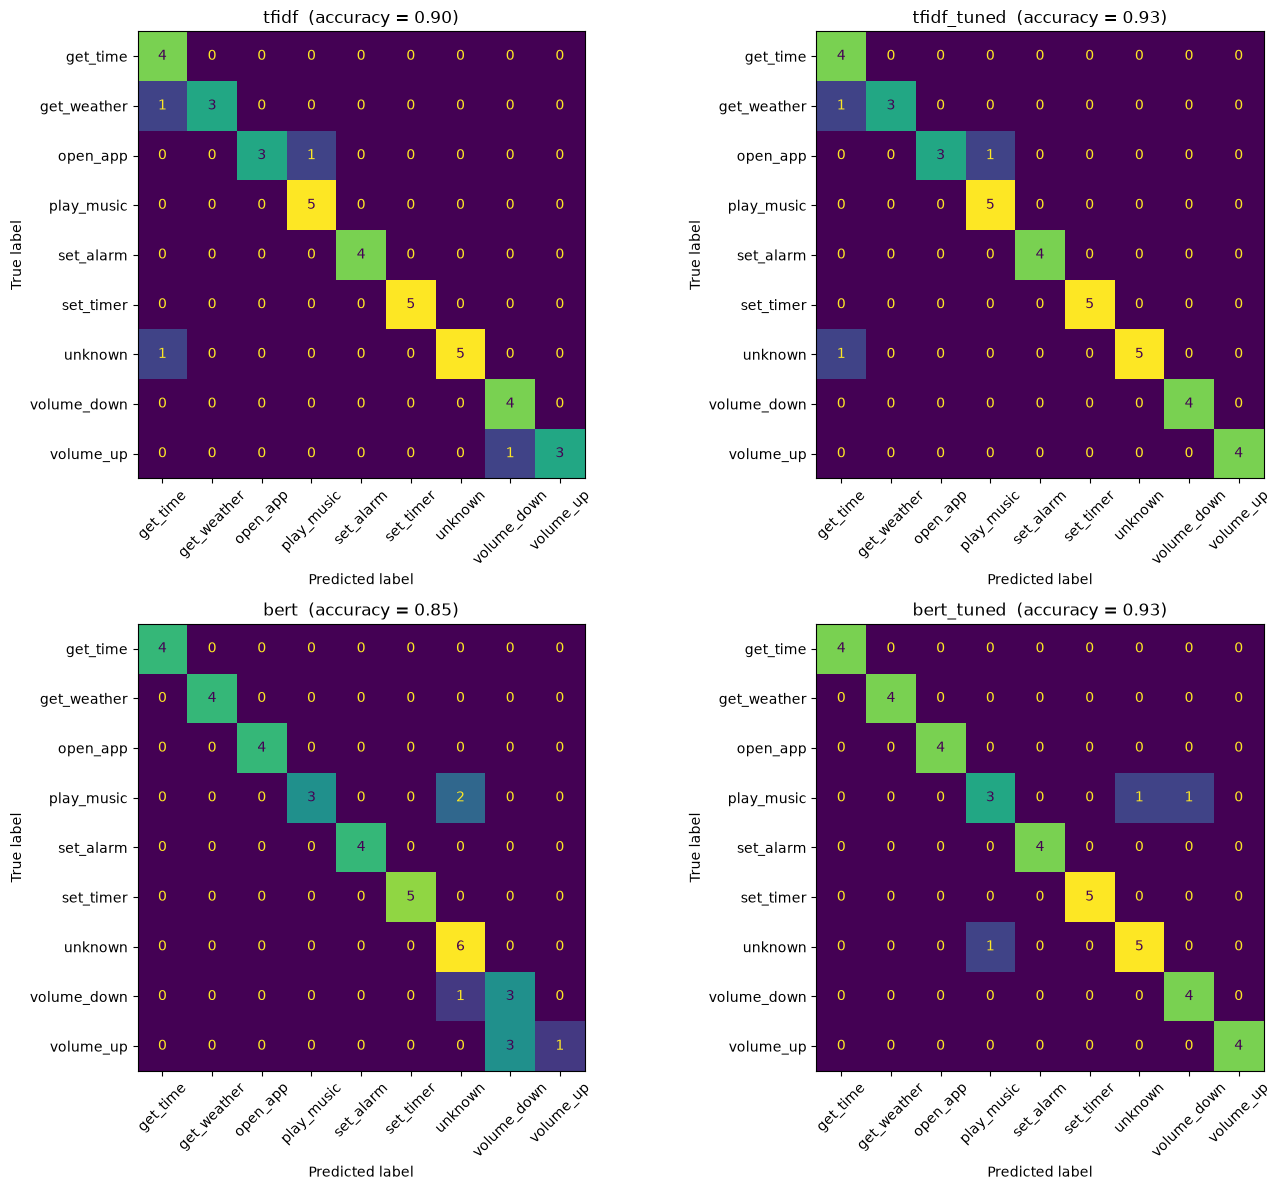

In [10]:
labels = sorted(train["intent"].unique())
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for ax, c in zip(axes.ravel(), cols):
    ConfusionMatrixDisplay.from_predictions(
        test_res["intent"], test_res[c], labels=labels, ax=ax,
        xticks_rotation=45, colorbar=False,
    )
    ax.set_title(f"{c}  (accuracy = {accuracy_score(test_res['intent'], test_res[c]):.2f})")
plt.tight_layout()
plt.savefig(RESULTS / "confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Кросс-валидация по всем данным

На 40 тестовых фразах одна ошибка меняет accuracy на 2,5 процентных пункта, поэтому одному разбиению доверять нельзя. Здесь данные 5 раз делятся на части (и так 3 раза с разным перемешиванием), и мы получаем среднее и разброс (`mean ± std`).

Для версий с подбором `C` используется **вложенная** кросс-валидация: `C` подбирается заново внутри каждой обучающей части, поэтому оценка не завышена.

In [11]:
df = pd.concat([train, test], ignore_index=True)
X_all = np.vstack([X_train, X_test])          # порядок тот же, что в df
outer = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

def cv_acc(name, estimator, X):
    s = cross_val_score(estimator, X, df["intent"], cv=outer, scoring="accuracy")
    print(f"{name:14} {s.mean():.3f} ± {s.std():.3f}")
    return float(s.mean()), float(s.std())

cv_res = {
    "tfidf": cv_acc("tfidf", make_tfidf(), df["text"]),
    "tfidf_tuned": cv_acc(
        "tfidf_tuned",
        GridSearchCV(make_tfidf(), {"logisticregression__C": CS}, cv=inner, scoring="f1_macro"),
        df["text"],
    ),
    "bert": cv_acc("bert", LogisticRegression(max_iter=3000), X_all),
    "bert_tuned": cv_acc(
        "bert_tuned",
        GridSearchCV(LogisticRegression(max_iter=3000), {"C": CS}, cv=inner, scoring="f1_macro"),
        X_all,
    ),
}

tfidf          0.808 ± 0.055
tfidf_tuned    0.825 ± 0.052
bert           0.843 ± 0.055
bert_tuned     0.898 ± 0.037


## 7. Самый важный тест: выходы Whisper (`hard_asr.csv`)

Это фразы, которые реально выдали Whisper tiny, base и small на шести записях (например, «Сделаю звук потише» или «какая сегодня порбона»). Они были исключены из обучения. Так проверяется, переживает ли «мозг» ошибки «ушей».

Для каждого ответа показана **уверенность** модели (максимальная вероятность). Низкая уверенность на ошибочных ответах это основа для порога «не понял, повтори».

In [12]:
fitted = {
    "tfidf": (tfidf, hard["text"]),
    "tfidf_tuned": (gs_tfidf, hard["text"]),
    "bert": (bert, X_hard),
    "bert_tuned": (gs_bert, X_hard),
}

hard_res = hard.copy()
for name, (model, X) in fitted.items():
    proba = model.predict_proba(X)
    hard_res[name] = model.classes_[proba.argmax(axis=1)]
    hard_res[name + "_conf"] = proba.max(axis=1).round(2)

acc_hard = pd.DataFrame({
    name: (hard_res[name] == hard_res["intent"]).groupby(hard_res["model"]).mean()
    for name in cols
}).loc[["tiny", "base", "small"]].round(2)

print("Доля верных интентов по моделям ASR (по 6 фраз на каждую):")
acc_hard

Доля верных интентов по моделям ASR (по 6 фраз на каждую):


,tfidf,tfidf_tuned,bert,bert_tuned
model,,,,
tiny,0.83,0.83,0.33,0.67
base,1.00,1.00,0.67,0.67
small,1.00,1.00,0.67,0.83


In [13]:
show_cols = ["model", "text", "intent"] + [c for n in cols for c in (n, n + "_conf")]
hard_wrong = hard_res[hard_res[cols].ne(hard_res["intent"], axis=0).any(axis=1)]
print(f"Ошибочных строк (хотя бы в одной модели): {len(hard_wrong)} из {len(hard_res)}")
hard_wrong[show_cols]

Ошибочных строк (хотя бы в одной модели): 8 из 18


,model,text,intent,tfidf,tfidf_conf,tfidf_tuned,tfidf_tuned_conf,bert,bert_conf,bert_tuned,bert_tuned_conf
0,tiny,разбудем меня в 1837,set_alarm,set_alarm,0.28,set_alarm,0.61,unknown,0.22,volume_up,0.51
2,tiny,запусти бралвер,open_app,open_app,0.34,open_app,0.86,unknown,0.21,open_app,0.60
4,tiny,делый зуб по громче,volume_up,volume_up,0.20,volume_up,0.51,volume_down,0.18,volume_up,0.55
5,tiny,какая сегодня порбона,get_weather,get_time,0.20,get_time,0.53,get_time,0.27,get_time,0.55
6,base,разбудем меня 1837,set_alarm,set_alarm,0.28,set_alarm,0.61,unknown,0.23,volume_up,0.64
10,base,делай зуб по громче,volume_up,volume_up,0.20,volume_up,0.51,volume_down,0.20,volume_down,0.71
12,small,разбуди меня в 1837,set_alarm,set_alarm,0.51,set_alarm,0.94,unknown,0.23,volume_up,0.37
16,small,делаю звук погромче,volume_up,volume_up,0.28,volume_up,0.79,volume_down,0.23,volume_up,0.97


## 8. Скорость и итоговая таблица

Замеряем время на одну фразу: для TF-IDF только классификация, для BERT получение вектора и классификация. Это без учёта Whisper.

In [14]:
def median_time(fn, n=50):
    ts = []
    for _ in range(n):
        t0 = time.perf_counter()
        fn()
        ts.append(time.perf_counter() - t0)
    return float(np.median(ts))

phrase = "поставь таймер на десять минут"
for _ in range(3):                      # прогрев
    embed_one(phrase)
    tfidf.predict([phrase])

times = {
    "tfidf": median_time(lambda: tfidf.predict([phrase])),
    "bert": median_time(lambda: bert.predict(embed_one(phrase).reshape(1, -1))),
}

rows = []
for name in cols:
    family = "tfidf" if name.startswith("tfidf") else "bert"
    rows.append({
        "model": name,
        "test_accuracy": accuracy_score(test_res["intent"], test_res[name]),
        "test_macro_f1": f1_score(test_res["intent"], test_res[name], average="macro"),
        "cv_acc_mean": cv_res[name][0],
        "cv_acc_std": cv_res[name][1],
        "hard_tiny": acc_hard.loc["tiny", name],
        "hard_base": acc_hard.loc["base", name],
        "hard_small": acc_hard.loc["small", name],
        "ms_per_phrase": times[family] * 1000,
    })

summary = pd.DataFrame(rows).round(3)
summary.to_csv(RESULTS / "intent_comparison.csv", index=False)
summary

,model,test_accuracy,test_macro_f1,cv_acc_mean,cv_acc_std,hard_tiny,hard_base,hard_small,ms_per_phrase
0,tfidf,0.900,0.898,0.808,0.055,0.83,1.00,1.00,1.502
1,tfidf_tuned,0.925,0.926,0.825,0.052,0.83,1.00,1.00,1.502
2,bert,0.850,0.839,0.843,0.055,0.33,0.67,0.67,7.164
3,bert_tuned,0.925,0.932,0.898,0.037,0.67,0.67,0.83,7.164


## 9. Выводы

Все цифры взяты из таблиц выше. Тест из 40 фраз и набор `hard_asr` (18 строк, но всего 6 разных команд, повторённых тремя моделями Whisper) очень малы, поэтому разницу в одну-две фразы нельзя считать значимой.

**1. Какая модель лучше и значима ли разница?**
На `test` результаты зависят от подбора `C`: без него TF-IDF точнее (0,900 против 0,850 у rubert-tiny2), с подбором обе дают 0,925, то есть по 3 ошибки из 40. На кросс-валидации по всем данным лучше rubert-tiny2 с подбором `C`: 0,898 ± 0,037 против 0,825 ± 0,052 у TF-IDF. Разница около 7 процентных пунктов, больше разброса каждой оценки, но повторные разбиения зависимы друг от друга, поэтому это вероятное преимущество, а не доказанное. Одно разбиение даёт завышенную оценку: у TF-IDF на `test` 0,925, а по кросс-валидации 0,825.

**2. Помог ли подбор `C`?**
Да, обеим моделям, и rubert-tiny2 больше. На `test`: TF-IDF 0,900 → 0,925, rubert-tiny2 0,850 → 0,925. По кросс-валидации: TF-IDF 0,808 → 0,825, rubert-tiny2 0,843 → 0,898. При `C=1` регуляризация слишком сильная: macro-F1 на кросс-валидации train у TF-IDF 0,66 против 0,75 при `C=10`, у rubert-tiny2 0,80 против 0,885 при `C=1000`. У rubert-tiny2 лучшее значение лежит на краю проверенной сетки, возможно, `C` выше было бы ещё лучше.

**3. Какие интенты путаются?**
- rubert-tiny2 с `C=1` путает «громче» и «тише»: 3 из 4 фраз `volume_up` ушли в `volume_down` («прибавь звук», «увеличь звук», «я ничего не слышу сделай громче»). Вероятно, эмбеддинги ставят антонимы рядом, потому что обе фразы про громкость. Подбор `C` это исправил.
- Оставшиеся ошибки rubert-tiny2 (с подбором `C`): «включи что-нибудь спокойное» → `volume_down`, «сыграй что-нибудь весёлое» → `unknown`, «сколько будет два плюс два» → `play_music`.
- У TF-IDF ошибки из-за общих слов: «скажи погоду в Алматы» → `get_time`, «включи камеру» → `play_music` (слово «включи» характерно для музыки), «сколько будет два плюс два» → `get_time` (слово «сколько»).
- Модели ошибаются по-разному: TF-IDF лексически, rubert-tiny2 по смысловой близости.

**4. Что происходит на выходе Whisper?**
TF-IDF точнее: 17 из 18 верных против 13 из 18 у rubert-tiny2 (с подбором `C`). У TF-IDF только одна ошибка на tiny, у base и small 6 из 6. Основная причина у rubert-tiny2: все три записи про будильник со временем «1837» (Whisper пишет время слитно цифрами) ушли в `volume_up`, тогда как TF-IDF удержали слова «разбуди меня в». Фраза «какая сегодня порбона» ошибочна у всех четырёх моделей: ключевое слово искажено полностью, остаётся «какая сегодня», похожее на вопросы о времени. Точность зависит от модели ASR сильнее, чем от выбора классификатора: на выходе small результат лучше всего.

**5. Помогает ли уверенность отсечь «не понял»?**
Нет. У TF-IDF (подбор `C`) ошибочный ответ на «порбона» имеет уверенность 0,53, а верные ответы бывают с 0,51. У rubert-tiny2 (подбор `C`) ошибочные ответы лежат в диапазоне 0,37-0,71, верные 0,55-0,97, диапазоны перекрываются. Простой порог по уверенности на этих данных надёжно не работает.

**6. Цена выигрыша по времени и качеству.**
Классификация одной фразы занимает около 1,5 мс у TF-IDF и 7,2 мс у rubert-tiny2 (медиана, CPU). Разница ничтожна на фоне распознавания речи (от 1 до 7 с у Whisper), поэтому узкое место ассистента это ASR, а не классификатор.

**7. Ограничения и дальнейшие шаги.**
- Мало данных: 196 фраз, один автор, один стиль формулировок.
- `hard_asr` содержит только 6 разных команд, строки зависимы друг от друга.
- Любое исправление, придуманное после просмотра ошибок `hard_asr`, будет подогнано под этот набор, для честной проверки нужны новые записи.
- Проверить: нормализацию чисел («1837» → «18 37») и больше фраз со временем в обучении, дообучение rubert-tiny2 целиком, более широкий набор данных (например, MASSIVE), `C` выше 1000.

**Итог.** Для прототипа ассистента выбран TF-IDF + логистическая регрессия (`C=10`): точнее на выходах Whisper и быстрее. Rubert-tiny2 лучше на данных своего стиля (по кросс-валидации), но хуже переносится на выходы распознавания речи, прежде всего из-за чисел.